# Task 3: Descriptive Statistics

**Objective:** Present basic statistics for the numerical columns.

**Steps:**
1. Identify the numerical columns.
2. Calculate the mean, median and standard deviation for each.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/Data_set_2.csv")

In [2]:
num_cols = df.select_dtypes(include="number").columns.tolist()
num_cols

['age',
 'Mutual_Funds',
 'Equity_Market',
 'Debentures',
 'Government_Bonds',
 'Fixed_Deposits',
 'PPF',
 'Gold']

In [3]:
stats = df[num_cols].agg(["mean", "median", "std"]).T.round(2)
stats

,mean,median,std
age,27.80,27.0,3.56
Mutual_Funds,2.55,2.0,1.20
Equity_Market,3.48,4.0,1.13
Debentures,5.75,6.5,1.68
Government_Bonds,4.65,5.0,1.37
Fixed_Deposits,3.58,3.5,1.80
PPF,2.02,1.0,1.61
Gold,5.98,6.0,1.14


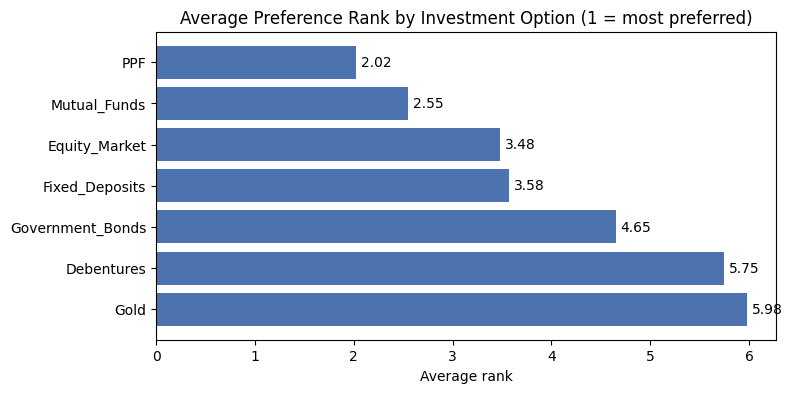

In [4]:
rank_cols = [c for c in num_cols if c != "age"]
mean_rank = df[rank_cols].mean().sort_values()

plt.figure(figsize=(8, 4))
bars = plt.barh(mean_rank.index, mean_rank.values, color="#4C72B0")
plt.gca().invert_yaxis()

for bar in bars:
    plt.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2,
             round(bar.get_width(), 2), va="center")

plt.title("Average Preference Rank by Investment Option (1 = most preferred)")
plt.xlabel("Average rank")
plt.savefig("../outputs/charts/task03_mean_rank.png", dpi=150, bbox_inches="tight")
plt.show()

## Finding

Age is the only true numeric measure. The mean age is 27.8, the median is 27 and the standard deviation is 3.56. Respondents are between 21 and 35 years old, so this is a young group.

The other seven numeric columns are preference ranks (1 = most preferred), so their averages show the average position, not an amount. The lowest (most preferred) average ranks are PPF (2.02), Mutual Funds (2.55), Equity (3.48). The least preferred are Debentures (5.75) and Gold (5.98).